# CNN Practical — Convolutional Neural Networks with PyTorch

**Topic:** Convolution, Pooling, Gradients, Receptive Field and CIFAR-10 Classifier  
**Framework:** PyTorch  
**Dataset:** CIFAR-10

### Aim
To understand the basic operations of a Convolutional Neural Network (CNN), verify calculations using PyTorch, trace tensors through a CNN, and train a small image classifier.

### Main concepts
- N, C, H, W tensor format
- Convolution / cross-correlation
- Stride and padding
- ReLU and gradients
- Max pooling and average pooling
- Backpropagation through convolution
- Parameters and receptive field
- CIFAR-10 classification

## Practical roadmap

1. Set up PyTorch
2. Understand image tensor shape
3. Perform convolution manually and with PyTorch
4. Verify the output-size formula
5. Study ReLU and its gradient
6. Compare max and average pooling
7. Observe gradients through pooling
8. Verify convolution gradients
9. Count parameters, receptive field and MACs
10. Load CIFAR-10
11. Build and trace a CNN
12. Train and evaluate the CNN
13. Visualize learned filters and feature maps



# Step 1 — Imports and Setup

We import PyTorch, torchvision and matplotlib. The `device` selects a GPU if available; otherwise CPU is used.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.11.0+cpu | device: cpu


### OBSERVATION

The output shows the installed PyTorch version and either `cuda` or `cpu`.

`F.conv2d` is useful when we provide a kernel ourselves, while `nn.Conv2d` is a learnable layer used inside a model.

# Step 2 — How PyTorch Stores an Image

PyTorch uses the **N, C, H, W** format:

- **N** = batch size
- **C** = channels
- **H** = height
- **W** = width

For one RGB image of size 32 × 32, the shape is `(1, 3, 32, 32)`.

In [ ]:
import torch

# Create a random 4D tensor with shape (Batch, Channels, Height, Width)
# This simulates 1 color image (RGB) with a resolution of 32x32 pixels
x = torch.rand(1, 3, 32, 32)

# Print the complete shape/dimensions of the tensor
print("tensor shape :", x.shape)

# Print the batch size (number of images in the batch)
print("N (batch) :", x.shape[0])

# Print the number of channels (e.g., 3 for RGB color channels)
print("C (channels) :", x.shape[1])

# Print the pixel height of the image
print("H (height) :", x.shape[2])

# Print the pixel width of the image
print("W (width) :", x.shape[3])


tensor shape : torch.Size([1, 3, 32, 32])
N (batch) : 1
C (channels) : 3
H (height) : 32
W (width) : 32


# Step 3 — Convolution by Hand and by PyTorch

We use the same 3 × 3 input and 2 × 2 kernel from the laboratory manual.

\[
Z(i,j)=\sum_m\sum_n X(i+m,j+n)K(m,n)
\]

PyTorch's `conv2d` performs cross-correlation, so the kernel is **not flipped**.

In [ ]:
import torch
import torch.nn.functional as F


# ---------------------------------------------------------
# INPUT IMAGE / MATRIX
# ---------------------------------------------------------
# X is a 3 × 3 input.
#
# Think of this as a very small grayscale image:
#
#        column →   0    1    2
# row 0             1    2    0
# row 1             0    1    3
# row 2             2    1    0

#
# Since this is a single-channel example, there is
# no separate channel dimension here yet.

X = torch.tensor([
    [1., 2., 0.],
    [0., 1., 3.],
    [2., 1., 0.]
])


# ---------------------------------------------------------
# KERNEL / FILTER
# ---------------------------------------------------------
# K is a 2 × 2 kernel.
#
#        column →   0    1
# row 0             1    0
# row 1            -1    1
#
# This kernel will move (slide) over the input X.

K = torch.tensor([
    [ 1., 0.],
    [-1., 1.]
])


# ---------------------------------------------------------
# CONVOLUTION / CROSS-CORRELATION FORMULA
# ---------------------------------------------------------
#
# Z(i,j) = b + Σ_m Σ_n X(i+m, j+n) * K(m,n)
#
# Here we do NOT use a bias, so:
#
# Z(i,j) = Σ_m Σ_n X(i+m, j+n) * K(m,n)
#
# In simple words:
#
# 1. Take a small patch from X.
# 2. Multiply the patch element-by-element with K.
# 3. Add all the multiplied values.
# 4. Store the result in the output at position (i,j).


# ---------------------------------------------------------
# CREATE OUTPUT MATRIX
# ---------------------------------------------------------
# Input  = 3 × 3
# Kernel = 2 × 2
# Stride = 1
# Padding = 0
#
# Therefore:
#
# Output size = (3 - 2) + 1 = 2
#
# So output will be:
#
#        2 × 2
#
# We initially fill it with zeros.

manual = torch.zeros(2, 2)


# ---------------------------------------------------------
# OUTER LOOP: MOVE KERNEL DOWN
# ---------------------------------------------------------
# range(2) gives:

# i = 0
# i = 1
#
# Why only 0 and 1?
#
# Because the 2×2 kernel can start at row 0 or row 1.
#
# Starting at row 2 would be impossible because
# the kernel needs TWO rows, but only one row would remain.

for i in range(2):


    # -----------------------------------------------------
    # INNER LOOP: MOVE KERNEL RIGHT
    # -----------------------------------------------------
    # j = 0
    # j = 1
    #
    # So the kernel visits four positions:
    #
    # (i,j) = (0,0)
    # (i,j) = (0,1)
    # (i,j) = (1,0)
    # (i,j) = (1,1)
    #
    # These four positions produce the four values
    # of the 2×2 output.

    for j in range(2):


        # -------------------------------------------------
        # EXTRACT A 2×2 PATCH FROM THE INPUT
        # -------------------------------------------------
        #
        # X[i:i+2, j:j+2]
        #
        # Python slicing is:
        #
        # start : end
        #
        # The START is included.
        # The END is NOT included.
        #
        # Therefore:
        #
        # i:i+2
        # means rows:
        #     i, i+1
        #
        # j:j+2
        # means columns:
        #     j, j+1
        #
        # Example:
        #
        # if i = 0 and j = 0:
        #
        # X[0:2, 0:2]
        #
        # gives:
        #
        # [[1, 2],
        #  [0, 1]]
        #
        # This is exactly the portion covered by the kernel.

        patch = X[i:i+2, j:j+2]


        # -------------------------------------------------
        # ELEMENT-WISE MULTIPLICATION
        # -------------------------------------------------
        #
        # patch * K
        #
        # multiplies corresponding elements:
        #
        # patch:
        # [[1, 2],
        #  [0, 1]]
        #
        # K:
        # [[ 1, 0],
        #  [-1, 1]]
        #
        # Result:
        # [[1*1, 2*0],
        #  [0*(-1), 1*1]]
        #
        # = [[1, 0],
        #    [0, 1]]
        #
        # Then .sum() adds ALL elements:
        #
        # 1 + 0 + 0 + 1 = 2
        #
        # So this gives ONE output value.

        manual[i, j] = (patch * K).sum()


# ---------------------------------------------------------
# PRINT THE MANUALLY CALCULATED OUTPUT
# ---------------------------------------------------------

print("hand-computed:\n", manual)


# =========================================================
# PYTORCH'S F.CONV2D VERSION
# =========================================================
#
# Instead of manually writing the two loops,
# PyTorch can perform the same operation using:
#
# F.conv2d()
#
# BUT F.conv2d expects the input in 4 dimensions:
#
# (N, C, H, W)
#
# N = batch size
# C = number of channels
# H = height
# W = width
#
# Currently X has shape:
#
# (3, 3)
#
# We need to convert it to:
#
# (1, 1, 3, 3)
#
# meaning:
#
# N = 1 image
# C = 1 channel
# H = 3
# W = 3


# X.view(1, 1, 3, 3)
#
# changes the SHAPE of X.
# It does NOT change its values.
#
# Before:
# [[1, 2, 0],
#  [0, 1, 3],
#  [2, 1, 0]]
#
# Shape = (3, 3)
#
# After view:
# Shape = (1, 1, 3, 3)


# ---------------------------------------------------------
# KERNEL SHAPE
# ---------------------------------------------------------
#
# F.conv2d expects kernel shape:
#
# (out_channels, in_channels, kernel_height, kernel_width)
#
# Our K is currently:
#
# (2, 2)
#
# We change it to:
#
# (1, 1, 2, 2)
#
# Meaning:
#
# out_channels  = 1
# in_channels   = 1
# kernel height = 2
# kernel width  = 2
#
# So we have ONE 2×2 filter operating on ONE input channel.


out = F.conv2d(
    X.view(1, 1, 3, 3),
    K.view(1, 1, 2, 2)
)


# ---------------------------------------------------------
# OUTPUT FROM F.CONV2D
# ---------------------------------------------------------
#
# F.conv2d produces shape:
#
# (N, out_channels, H_out, W_out)
#
# Here:
#
# N = 1
# out_channels = 1
# H_out = 2
# W_out = 2
#
# Therefore:
#
# output shape = (1, 1, 2, 2)
#
# We use .view(2,2) to remove the unnecessary
# batch and channel dimensions for easy display.
#
# So:
#
# (1,1,2,2) → (2,2)


print("F.conv2d     :\n", out.view(2, 2))


# ---------------------------------------------------------
# CHECK WHETHER BOTH RESULTS ARE IDENTICAL
# ---------------------------------------------------------
#
# manual:
#     result obtained using our own loops
#
# out.view(2,2):
#     result obtained using PyTorch
#
# torch.allclose() checks whether the two tensors
# contain the same (or sufficiently close) values.
#
# If they are the same:
#
#     True
#
# This proves that our manual convolution calculation
# and PyTorch's F.conv2d are giving the same result.

print(
    "identical    :",
    torch.allclose(manual, out.view(2, 2))
)

hand-computed:
 tensor([[ 2.,  4.],
        [-1.,  0.]])
F.conv2d     :
 tensor([[ 2.,  4.],
        [-1.,  0.]])
identical    : True


# Step 4 — Stride, Padding and Output Size

The output-size formula is:

\[
H_{out}=\left\lfloor\frac{H+2P-K}{S}\right\rfloor+1
\]

where `H` = input size, `K` = kernel size, `S` = stride and `P` = padding.

In [ ]:
import torch
import torch.nn as nn


# =========================================================
# FUNCTION TO CALCULATE OUTPUT SIZE
# =========================================================
#
# Convolution output-size formula:
#
#              H + 2P - K
# H_out = floor(---------------) + 1
#                     S
#
# H = input height
# K = kernel size
# S = stride
# P = padding
#
# Example:
# H = 32, K = 3, S = 1, P = 1
#
# H_out = floor((32 + 2(1) - 3) / 1) + 1
#       = floor(31 / 1) + 1
#       = 32
#
# // in Python performs floor division.
# For these positive values, it gives the same integer
# result as the floor operation in the formula.


def output_size(H, K, S, P):

    # Calculate the spatial output size using the formula.
    #
    # 2*P means padding is applied on BOTH sides:
    # left + right, or top + bottom.
    #
    # K is subtracted because the kernel occupies K positions.
    #
    # Division by S accounts for the stride.
    #
    # +1 represents the first valid position of the kernel.

    return (H + 2*P - K) // S + 1


# =========================================================
# DIFFERENT CONVOLUTION SETTINGS
# =========================================================
#
# Each tuple contains:
#
# (H, K, S, P)
#
# H = input height/width
# K = kernel size
# S = stride
# P = padding
#
# We use square inputs and square kernels here, so
# height and width have the same value.


settings = [

    (32, 3, 1, 1),   # Stride 1, padding 1 → SAME spatial size

    (64, 5, 2, 2),   # Stride 2, padding 2 → output becomes 32, NOT same size

    (28, 3, 1, 0),   # No padding (valid) → output becomes smaller

    (32, 3, 1, 2)    # More padding → output becomes larger

]


# =========================================================
# TEST EVERY SETTING
# =========================================================
#
# The loop takes one tuple at a time.
#
# For example, first iteration:
#
# h = 32
# k = 3
# s = 1
# p = 1
#
# Then the next tuple is used, and so on.


# Lowercase names are used here so that the X and K
# variables from Experiment 2 are not overwritten.

for h, k, s, p in settings:


    # -----------------------------------------------------
    # CREATE A PYTORCH CONVOLUTION LAYER
    # -----------------------------------------------------
    #
    # nn.Conv2d arguments:
    #
    # nn.Conv2d(in_channels,
    #           out_channels,
    #           kernel_size,
    #           stride,
    #           padding)
    #
    # Here:
    #
    # in_channels  = 1
    # out_channels = 1
    # kernel_size  = k
    # stride       = s
    # padding      = p
    # nn.conv2d() creates trninable kernel layer. you dont provide kernel.
    # We are only interested in checking the output SIZE,
    # not the actual values of the convolution.


    layer = nn.Conv2d(
        1,                  # 1 input channel
        1,                  # 1 output channel
        kernel_size=k,      # K = kernel size
        stride=s,           # S = stride
        padding=p           # P = padding
    )


    # -----------------------------------------------------
    # GIVE PYTORCH A DUMMY INPUT
    # -----------------------------------------------------
    #
    # torch.zeros(1, 1, h, h)
    #
    # creates a tensor with shape:
    #
    # (N, C, H, W)
    #
    # N = 1 image
    # C = 1 channel
    # H = h
    # W = h
    #
    # Example when h = 32:
    #
    # shape = (1, 1, 32, 32)
    #
    # The actual values are all zero.
    # We don't care about the values here.
    # We only want to know the resulting output size.


    actual = layer(
        torch.zeros(1, 1, h, h)
    ).shape[-1]


    # -----------------------------------------------------
    # WHAT DOES .shape[-1] MEAN?
    # -----------------------------------------------------
    #
    # The output of Conv2d has shape:
    #
    # (N, C, H_out, W_out)
    #
    # For example:
    #
    # (1, 1, 32, 32)
    #
    # Python indexing:
    #
    # shape[0] -> N
    # shape[1] -> C
    # shape[2] -> H_out
    # shape[3] -> W_out
    #
    # shape[-1] means:
    # "take the LAST dimension"
    #
    # Therefore shape[-1] gives W_out.
    #
    # Since we are using a square input and square kernel,
    # H_out = W_out.
    #
    # So shape[-1] gives us the output spatial dimension.


    # -----------------------------------------------------
    # CALCULATE THE SAME SIZE USING OUR FORMULA
    # -----------------------------------------------------
    #
    # This is the answer calculated manually using:
    #
    # floor((H + 2P - K) / S) + 1


    expected = output_size(h, k, s, p)


    # -----------------------------------------------------
    # PRINT BOTH RESULTS
    # -----------------------------------------------------
    #
    # We compare:
    #
    # expected = calculated using our formula
    #
    # actual = calculated by PyTorch
    #
    # If they are equal:
    #
    #     "ok"
    #
    # Otherwise:
    #
    #     "MISMATCH"


    print(
        f"H={h:3d} K={k} S={s} P={p} -> "
        f"formula {expected:3d}"
        f"   PyTorch {actual:3d}"
        f"   {'ok' if expected == actual else 'MISMATCH'}"
    )

H= 32 K=3 S=1 P=1 -> formula  32   PyTorch  32   ok
H= 64 K=5 S=2 P=2 -> formula  32   PyTorch  32   ok
H= 28 K=3 S=1 P=0 -> formula  26   PyTorch  26   ok
H= 32 K=3 S=1 P=2 -> formula  34   PyTorch  34   ok




With `stride = 1` and `P = (K-1)/2`, an odd-sized kernel preserves spatial size.

# Step 5 — ReLU and Its Gradient

ReLU is:

\[
ReLU(x)=\max(0,x)
\]

For positive values its derivative is 1; for negative values it is 0. PyTorch autograd calculates the gradient automatically.

In [ ]:
import torch
import torch.nn.functional as F


# ---------------------------------------------------------
# FEATURE MAP
# ---------------------------------------------------------
# This is a 2 × 3 feature map.
#
# It contains both positive and negative values:
#
#     -2    3   -1
#      4    0   -5
#
# ReLU will keep positive values and replace
# negative values with 0.
#
# ReLU formula:
#
# ReLU(x) = max(0, x)

fm = torch.tensor([
    [-2., 3., -1.],
    [ 4., 0., -5.]
])


# ---------------------------------------------------------
# APPLY ReLU
# ---------------------------------------------------------
# F.relu(fm) applies ReLU to EVERY element.
#
# Negative values → 0
# Positive values → unchanged
# Zero → remains 0
#
# Therefore:
#
# Input:
# [[-2,  3, -1],
#  [ 4,  0, -5]]
#
# After ReLU:
# [[ 0,  3,  0],
#  [ 4,  0,  0]]

print("after ReLU:\n", F.relu(fm))


# ---------------------------------------------------------
# CREATE A COPY FOR GRADIENT CALCULATION
# ---------------------------------------------------------
# clone() creates a copy of fm.
#
# We use a separate variable z because we want to calculate
# the gradient of ReLU with respect to its input.
#
# requires_grad_(True) tells PyTorch:
#
# "Track all operations involving z because I will
#  calculate gradients later."

# Make a copy of fm and enable gradient tracking for that copy.
z = fm.clone().requires_grad_(True)


# ---------------------------------------------------------
# BACKPROPAGATION
# ---------------------------------------------------------
#
# F.relu(z)
#     ↓
# Apply ReLU to z
#
# .sum()
#     ↓
# Add all ReLU output values together.
#
# .backward()
#     ↓
# Perform backpropagation and calculate:
#
# d(ReLU output sum) / dz
#
# PyTorch stores the resulting gradient inside:
#
# z.grad


F.relu(z).sum().backward()


# ---------------------------------------------------------
# DISPLAY THE GRADIENT
# ---------------------------------------------------------
# z.grad contains the gradient of the output with respect
# to each element of z.
#
# For ReLU:
#
#        1, if z > 0
# d/dz = 0, if z < 0
#
# At z = 0, the derivative depends on the convention used
# by the implementation; PyTorch uses 0 here.
#
# Our input:
#
# [[-2, 3, -1],
#  [ 4, 0, -5]]
#
# Therefore gradient:
#
# [[0, 1, 0],
#  [1, 0, 0]]

print("d(ReLU)/dz:\n", z.grad)

after ReLU:
 tensor([[0., 3., 0.],
        [4., 0., 0.]])
d(ReLU)/dz:
 tensor([[0., 1., 0.],
        [1., 0., 0.]])


### OBSERVATION

```text
after ReLU:
tensor([[0., 3., 0.],
        [4., 0., 0.]])

d(ReLU)/dz:
tensor([[0., 1., 0.],
        [1., 0., 0.]])
```

At exactly zero, PyTorch uses gradient 0 for ReLU.

# Step 6 — Max Pooling and Average Pooling

For a 2 × 2 window:

- **Max pooling:** keeps the largest value.
- **Average pooling:** calculates the mean.

Neither operation has learnable parameters.

In [ ]:
# Create a 4 × 4 input matrix
M = torch.tensor([
    [1., 9., 2., 4.],
    [3., 5., 7., 0.],
    [8., 6., 2., 1.],
    [4., 3., 9., 5.]
]).view(1, 1, 4, 4)
# .view(1, 1, 4, 4) changes the shape to:
# (N, C, H, W) = (1, 1, 4, 4)
# N = 1 image, C = 1 channel, H = 4, W = 4


# ---------------- MAX POOLING ----------------

print(
    "max pooling:\n",
    F.max_pool2d(
        M,
        kernel_size=2,   # Take a 2 × 2 window at a time
        stride=2         # Move the window 2 positions at a time
    ).view(2, 2)         # Convert output into a 2 × 2 matrix
)

# Max pooling selects the LARGEST value from each 2 × 2 window.


# ---------------- AVG POOLING ----------------

print(
    "avg pooling:\n",
    F.avg_pool2d(
        M,
        kernel_size=2,   # Take a 2 × 2 window at a time
        stride=2         # Move the window 2 positions at a time
    ).view(2, 2)         # Convert output into a 2 × 2 matrix
)

# Average pooling calculates the AVERAGE of each 2 × 2 window.

max pooling:
 tensor([[9., 7.],
        [8., 9.]])
avg pooling:
 tensor([[4.5000, 3.2500],
        [5.2500, 4.2500]])


# Step 7 — Gradient Flow Through Pooling

For **max pooling**, the gradient goes to the winning element in each window.

For **average pooling**, the incoming gradient is divided equally among all elements of the window.

In [ ]:
# Create the upstream gradient
upstream = torch.tensor([
    [1., 2.],
    [3., 4.]
]).view(1, 1, 2, 2)

# Upstream has the same shape as the pooling output: (1, 1, 2, 2)
# It represents the gradient coming BACK from the next layer.


# Test both types of pooling: Max Pooling and Average Pooling
for name, pool in [
    ("max", F.max_pool2d),
    ("avg", F.avg_pool2d)
]:

    # Make a copy of the input matrix M
    # clone() prevents us from modifying the original M
    # requires_grad_(True) tells PyTorch to calculate gradients for x
    x = M.clone().requires_grad_(True)

    # Apply pooling to the input
    # kernel_size=2 → use a 2 × 2 window
    # stride=2 → move the window by 2 positions
    y = pool(x, kernel_size=2, stride=2)

    # Backpropagate the upstream gradient through the pooling operation
    # This calculates how the gradient reaches the original input x
    y.backward(upstream)

    # Print which pooling operation was used
    print(f"gradient reaching the input, {name} pooling:")

    # x.grad contains the gradient of the input M
    # .view(4, 4) changes it back into a 4 × 4 matrix for easy viewing
    print(x.grad.view(4, 4), "\n")

gradient reaching the input, max pooling:
tensor([[0., 1., 0., 0.],
        [0., 0., 2., 0.],
        [3., 0., 0., 0.],
        [0., 0., 4., 0.]]) 

gradient reaching the input, avg pooling:
tensor([[0.2500, 0.2500, 0.5000, 0.5000],
        [0.2500, 0.2500, 0.5000, 0.5000],
        [0.7500, 0.7500, 1.0000, 1.0000],
        [0.7500, 0.7500, 1.0000, 1.0000]]) 



### Important observation

Max pooling produces a **sparse gradient** because only the maximum element receives the gradient.

Average pooling produces a **dense gradient** because every element receives part of the gradient.

# Step 8 — Backpropagation Through a Convolution Layer

We verify the three gradients from the manual derivation:

- `dL/db = 2`
- `dL/dK = [[2, 5], [1, 1]]`
- `dL/dX = [[1, 0, 0], [-1, 2, 0], [0, -1, 1]]`

The upstream gradient is `[[1, 0], [0, 1]]`.

In [ ]:
X_grad = X.view(1, 1, 3, 3).clone().requires_grad_(True)

conv = nn.Conv2d(1, 1, kernel_size=2)

with torch.no_grad():
    conv.weight.copy_(K.view(1, 1, 2, 2))
    conv.bias.zero_()

delta = torch.tensor([
    [1., 0.],
    [0., 1.]
]).view(1, 1, 2, 2)

Z = conv(X_grad)
Z.backward(delta)

print("dL/db =", conv.bias.grad.item())
print("dL/dK =\n", conv.weight.grad.view(2, 2))
print("dL/dX =\n", X_grad.grad.view(3, 3))

dL/db = 2.0
dL/dK =
 tensor([[2., 5.],
        [1., 1.]])
dL/dX =
 tensor([[ 1.,  0.,  0.],
        [-1.,  2.,  0.],
        [ 0., -1.,  1.]])


# Step 9 — Parameters, Receptive Field and Computational Cost

For a convolution layer:

\[
Parameters=K\times K\times C_{in}\times C_{out}+C_{out}
\]

The last term is the bias.

The receptive-field recurrence is:

\[
r_{new}=r+(k-1)\times jump
\]

\[
jump_{new}=jump\times stride
\]

In [ ]:
# Create a convolutional layer with:
# 32 input channels
# 64 output channels (filters)
# 3 × 3 kernel

layer = nn.Conv2d(
    in_channels=32,     # Number of input channels
    out_channels=64,    # Number of filters / output channels
    kernel_size=3       # Each filter is 3 × 3
)

# Count the total number of trainable parameters.
# p.numel() gives the number of elements in each parameter tensor.
# sum(...) adds the number of elements of all parameters.
print(
    "parameters:",
    sum(p.numel() for p in layer.parameters()),
    " = 3*3*32*64 weights + 64 biases"
)

# Number of weights:
# 3 × 3 × 32 × 64 = 18,432
#
# Number of biases:
# 64 (one bias for each filter)
#
# Total parameters:
# 18,432 + 64 = 18,496


# ---------------------------------------------------------
# Q7: Compare one 5 × 5 convolution with two 3 × 3 convolutions
# ---------------------------------------------------------

# One 5 × 5 convolution layer
# 1 input channel → 1 output channel
# bias=False means there are NO bias parameters.
one_5x5 = nn.Conv2d(
    1,              # input channels
    1,              # output channels
    5,              # 5 × 5 kernel
    bias=False      # Do not use bias
)


# Two 3 × 3 convolution layers stacked one after another
two_3x3 = nn.Sequential(
    nn.Conv2d(
        1,              # 1 input channel
        1,              # 1 output channel
        3,              # 3 × 3 kernel
        bias=False      # No bias
    ),

    nn.Conv2d(
        1,              # 1 input channel
        1,              # 1 output channel
        3,              # 3 × 3 kernel
        bias=False      # No bias
    )
)

# Count parameters in the single 5 × 5 layer
print(
    "one 5x5:",
    sum(p.numel() for p in one_5x5.parameters()),
    "weights"
)

# 5 × 5 × 1 × 1 = 25 weights


# Count parameters in both 3 × 3 layers
print(
    "two 3x3:",
    sum(p.numel() for p in two_3x3.parameters()),
    "weights"
)

# First 3 × 3 layer → 3 × 3 = 9 weights
# Second 3 × 3 layer → 3 × 3 = 9 weights
# Total → 9 + 9 = 18 weights


# ---------------------------------------------------------
# Section 6.1: Receptive Field
# ---------------------------------------------------------

# This function calculates the receptive field of a sequence
# of convolutional/pooling layers.

def receptive_field(kernels, strides):

    # Initially, one output value corresponds to one input value.
    r = 1

    # "jump" tells us how far apart two neighboring receptive
    # fields are in the original input.
    jump = 1

    # Go through each kernel size and stride together.
    for k, s in zip(kernels, strides):

        # Increase the receptive field according to:
        # r_new = r_old + (k - 1) × jump
        r += (k - 1) * jump

        # Update the jump for the next layer.
        jump *= s

    # Return the final receptive field size.
    return r


# Two 3 × 3 convolution layers, both with stride 1
print(
    "RF, two 3x3 stride-1 layers  :",
    receptive_field([3, 3], [1, 1])
)

# Receptive field = 5 × 5


# Three 3 × 3 convolution layers, all with stride 1
print(
    "RF, three 3x3 stride-1 layers:",
    receptive_field([3, 3, 3], [1, 1, 1])
)

# Receptive field = 7 × 7


# ---------------------------------------------------------
# Q9: MACs
# ---------------------------------------------------------

# Output feature map has:
# Height = 32
# Width  = 32
H_out = W_out = 32

# Calculate the number of Multiply-Accumulate operations (MACs).
#
# Formula:
# MACs =
# H_out × W_out × kernel_height × kernel_width
# × input_channels × output_channels

print(
    "MACs:",
    H_out * W_out * 3 * 3 * 1 * 16
)

# Here:
# H_out = 32
# W_out = 32
# Kernel = 3 × 3
# Input channels = 1
# Output channels = 16
#
# Therefore:
# MACs = 32 × 32 × 3 × 3 × 1 × 16
#      = 147,456

parameters: 18496  = 3*3*32*64 weights + 64 biases
one 5x5: 25 weights
two 3x3: 18 weights
RF, two 3x3 stride-1 layers  : 5
RF, three 3x3 stride-1 layers: 7
MACs: 147456


# Step 10 — Load CIFAR-10

CIFAR-10 contains 60,000 colour images of size 32 × 32 across 10 classes: 50,000 training images and 10,000 test images.

**This cell downloads the dataset. Run it only when you are ready to use CIFAR-10.**

In [ ]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )
])

train_set = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_set = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = torch.utils.data.DataLoader(
    train_set,
    batch_size=64,
    shuffle=True
)

test_loader = torch.utils.data.DataLoader(
    test_set,
    batch_size=64,
    shuffle=False
)

classes = (
    "plane", "car", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
)

print(len(train_set), "training images |", len(test_set), "test images")
print("one image:", train_set[0][0].shape, "| label:", classes[train_set[0][1]])

100%|██████████| 170M/170M [34:23<00:00, 82.6kB/s]


50000 training images | 10000 test images
one image: torch.Size([3, 32, 32]) | label: frog


## Display a CIFAR-10 batch

The normalization is undone using `img / 2 + 0.5`. `permute(1, 2, 0)` changes the tensor from `(C,H,W)` to `(H,W,C)` for matplotlib.

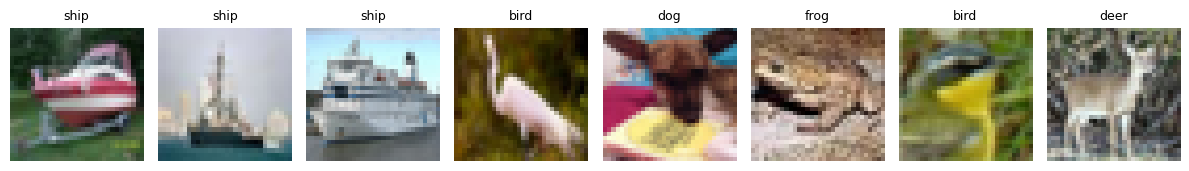

In [ ]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(1, 8, figsize=(12, 2))

for ax, img, lab in zip(axes, images[:8], labels[:8]):
    ax.imshow((img / 2 + 0.5).permute(1, 2, 0))
    ax.set_title(classes[lab], fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Step 11 — Build the CNN

Architecture:

```text
Input: 3 × 32 × 32
        ↓
Conv2d: 3 → 16, 3×3, padding=1
        ↓ ReLU
MaxPool 2×2
        ↓
16 × 16 × 16
        ↓
Conv2d: 16 → 32, 3×3, padding=1
        ↓ ReLU
MaxPool 2×2
        ↓
32 × 8 × 8
        ↓
Flatten → 2048
        ↓
Linear 2048 → 128
        ↓ ReLU
Linear 128 → 10
```

Both convolutions preserve spatial size because `padding=1`. The pooling layers reduce the spatial dimensions.

In [ ]:
# Define a CNN model by creating a class that inherits from nn.Module
class SmallCNN(nn.Module):

    # __init__() is called when we create the model
    def __init__(self, num_classes=10):

        # Initialize the parent nn.Module class
        super().__init__()


        # ---------------------------------------------------------
        # CONVOLUTIONAL LAYER 1
        # ---------------------------------------------------------

        self.conv1 = nn.Conv2d(
            3,                  # 3 input channels → RGB
            16,                 # 16 filters → 16 output channels
            kernel_size=3,      # 3 × 3 kernel
            padding=1           # Add 1 pixel padding around the image
        )

        # Input:
        #     3 × 32 × 32
        #
        # Output:
        #     16 × 32 × 32
        #
        # Because kernel=3, padding=1 and stride=1,
        # the height and width remain 32.


        # ---------------------------------------------------------
        # CONVOLUTIONAL LAYER 2
        # ---------------------------------------------------------

        self.conv2 = nn.Conv2d(
            16,                 # 16 input channels
            32,                 # 32 filters → 32 output channels
            kernel_size=3,      # 3 × 3 kernel
            padding=1           # Preserve height and width
        )

        # Input:
        #     16 × 16 × 16
        #
        # Output:
        #     32 × 16 × 16
        #
        # The number of channels changes from 16 → 32.


        # ---------------------------------------------------------
        # MAX POOLING LAYER
        # ---------------------------------------------------------

        self.pool = nn.MaxPool2d(
            kernel_size=2,      # Use a 2 × 2 window
            stride=2            # Move the window by 2 pixels
        )

        # Max pooling reduces the spatial dimensions by half:
        #
        # 32 × 32 → 16 × 16
        # 16 × 16 → 8 × 8
        #
        # It does NOT change the number of channels.


        # ---------------------------------------------------------
        # FULLY CONNECTED LAYER 1
        # ---------------------------------------------------------

        self.fc1 = nn.Linear(
            32 * 8 * 8,          # Number of inputs = 2048
            128                  # 128 neurons
        )

        # After the two convolution + pooling blocks:
        #
        # 32 channels × 8 height × 8 width
        # = 32 × 8 × 8
        # = 2048 values
        #
        # These 2048 values are given to fc1.


        # ---------------------------------------------------------
        # FULLY CONNECTED LAYER 2
        # ---------------------------------------------------------

        self.fc2 = nn.Linear(
            128,                 # Input: 128 values
            num_classes          # Output: 10 classes for CIFAR-10
        )

        # Final output contains 10 values,
        # one score for each CIFAR-10 class.


    # ---------------------------------------------------------
    # FORWARD PASS
    # ---------------------------------------------------------

    def forward(self, x):

        # First convolution → ReLU → max pooling
        #
        # Input:
        #     3 × 32 × 32
        #
        # Conv1:
        #     3 × 32 × 32 → 16 × 32 × 32
        #
        # ReLU:
        #     negative values become 0
        #
        # Max Pool:
        #     16 × 32 × 32 → 16 × 16 × 16

        x = self.pool(
            F.relu(
                self.conv1(x)
            )
        )


        # Second convolution → ReLU → max pooling
        #
        # Input:
        #     16 × 16 × 16
        #
        # Conv2:
        #     16 × 16 × 16 → 32 × 16 × 16
        #
        # ReLU:
        #     negative values become 0
        #
        # Max Pool:
        #     32 × 16 × 16 → 32 × 8 × 8

        x = self.pool(
            F.relu(
                self.conv2(x)
            )
        )


        # ---------------------------------------------------------
        # FLATTEN
        # ---------------------------------------------------------

        # Convert the 3D feature map into one long vector.
        #
        # Before:
        #     32 × 8 × 8
        #
        # After:
        #     32 × 8 × 8 = 2048
        #
        # "1" means: keep dimension 0 (the batch dimension)
        # and flatten everything after it.

        x = torch.flatten(x, 1)


        # ---------------------------------------------------------
        # FULLY CONNECTED LAYER 1
        # ---------------------------------------------------------

        # 2048 inputs → 128 neurons
        # ReLU adds non-linearity.

        x = F.relu(self.fc1(x))


        # ---------------------------------------------------------
        # FULLY CONNECTED LAYER 2
        # ---------------------------------------------------------

        # 128 → 10
        #
        # Returns 10 raw scores called "logits".
        #
        # No softmax is applied here because CrossEntropyLoss
        # can directly work with raw logits.

        return self.fc2(x)


# ---------------------------------------------------------
# CREATE THE MODEL
# ---------------------------------------------------------

# Create an object of the SmallCNN class
# and move it to the selected device (CPU/GPU).

model = SmallCNN().to(device)


# Print the complete model architecture
print(model)

SmallCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=2048, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


# Step 12 — Trace One Image Through the CNN

In [ ]:
x = torch.rand(1, 3, 32, 32).to(device)

print("input        ", tuple(x.shape))

h = model.conv1(x)
print("after conv1  ", tuple(h.shape))

h = model.pool(F.relu(h))
print("after pool1  ", tuple(h.shape))

h = model.conv2(h)
print("after conv2  ", tuple(h.shape))

h = model.pool(F.relu(h))
print("after pool2  ", tuple(h.shape))

h = torch.flatten(h, 1)
print("after flatten", tuple(h.shape))

print("logits       ", tuple(model(x).shape))

input         (1, 3, 32, 32)
after conv1   (1, 16, 32, 32)
after pool1   (1, 16, 16, 16)
after conv2   (1, 32, 16, 16)
after pool2   (1, 32, 8, 8)
after flatten (1, 2048)
logits        (1, 10)


## Count model parameters

In [ ]:
# Loop through all trainable and non-trainable weight matrices and bias vectors in the model
for name, p in model.named_parameters():
    print(
        # Prints the layer/parameter name (padded to 12 characters for alignment)
        f"{name:12s}",
        # Converts the tensor shape to a string tuple (padded to 18 characters)
        f"{str(tuple(p.shape)):18s}",
        # Prints the total number of individual elements in this specific parameter tensor
        f"{p.numel():>7d}"
    )

# Computes and prints the grand total of all weights and biases in the network
print("total parameters:", sum(p.numel() for p in model.parameters()))


conv1.weight (16, 3, 3, 3)          432
conv1.bias   (16,)                   16
conv2.weight (32, 16, 3, 3)        4608
conv2.bias   (32,)                   32
fc1.weight   (128, 2048)         262144
fc1.bias     (128,)                 128
fc2.weight   (10, 128)             1280
fc2.bias     (10,)                   10
total parameters: 268650



The first fully connected layer holds most of the model's parameters.

# Step 13 — Train the CNN

Each training iteration performs:

1. Forward pass
2. Loss calculation
3. Backward pass
4. Parameter update

`optimizer.zero_grad()` is used because PyTorch accumulates gradients.

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

EPOCHS = 5

for epoch in range(1, EPOCHS + 1):

    model.train()
    running = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running += loss.item() * images.size(0)

    epoch_loss = running / len(train_set)

    print(f"epoch {epoch} training loss {epoch_loss:.4f}")

epoch 1 training loss 1.4550
epoch 2 training loss 1.0927
epoch 3 training loss 0.9512
epoch 4 training loss 0.8484
epoch 5 training loss 0.7739




The training loss should generally decrease across the five epochs.



# Step 14 — Evaluate the CNN

`model.eval()` switches to evaluation mode and `torch.no_grad()` prevents unnecessary gradient calculation. The test loop does not update weights.

In [ ]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        predicted = model(images).argmax(dim=1)

        correct += (predicted == labels).sum().item()
        total += labels.size(0)

accuracy = 100 * correct / total

print(f"test accuracy: {accuracy:.2f}%")

test accuracy: 66.16%


# Step 15 — Accuracy for Each Class

In [ ]:
# Initialize tensors to track correct predictions and total samples for each of the 10 CIFAR-10 classes
correct_per_class = torch.zeros(10)
total_per_class = torch.zeros(10)

# Set the model to evaluation mode (disables dropout, batch normalization updates, etc.)
model.eval()

# Disable gradient calculation to save memory and speed up computation during inference
with torch.no_grad():

    # Loop through the test dataset in batches
    for images, labels in test_loader:

        # Move images to the active device (GPU/CPU), pass them through the model,
        # find the index of the highest logit (prediction), and move results back to CPU
        predicted = model(images.to(device)).argmax(dim=1).cpu()

        # Update statistics for each class individually
        for c in range(10):
            # Create a boolean mask identifying all ground-truth labels belonging to class 'c'
            mask = labels == c

            # Count and accumulate how many predictions match class 'c' within this masked subset
            correct_per_class[c] += (predicted[mask] == c).sum()

            # Accumulate the total number of actual occurrences of class 'c' in this batch
            total_per_class[c] += mask.sum()

# Print the final accuracy percentage for each individual class
for c in range(10):
    # Calculate the percentage accuracy for the current class
    class_accuracy = 100 * correct_per_class[c] / total_per_class[c]

    # Print the class name (padded to 6 characters) alongside its formatted accuracy value
    print(f"{classes[c]:6s} {class_accuracy:5.1f}%")


plane   33.9%
car      0.0%
bird     0.0%
cat      0.9%
deer     0.0%
dog     53.0%
frog    38.3%
horse    0.1%
ship     0.0%
truck    0.0%


# Step 16 — Visualize the Learned Conv1 Filters

The first convolution layer contains 16 filters of shape `3 × 3 × 3`. They are learned from the training data.

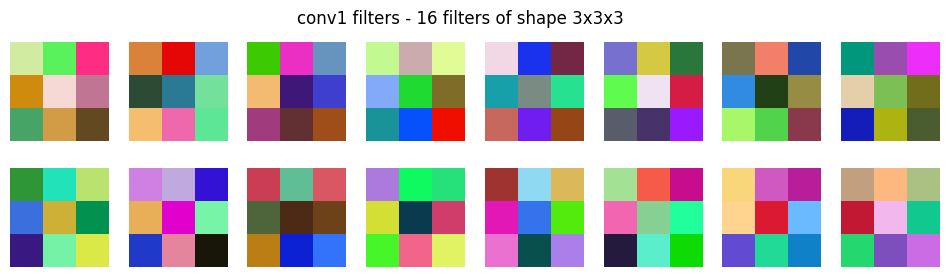

In [ ]:
# Extract the weights of the first convolutional layer and move them to the CPU
w = model.conv1.weight.data.cpu()

# Normalize the weights to the [0, 1] range so they can be correctly rendered as RGB images
w = (w - w.min()) / (w.max() - w.min())

# Create a grid of subplots with 2 rows and 8 columns to display all 16 filters
fig, axes = plt.subplots(2, 8, figsize=(12, 3))

# Flatten the axes array and iterate through each subplot alongside its corresponding filter weights
for ax, filt in zip(axes.flat, w):
    # Rearrange dimensions from PyTorch format (Channels, Height, Width) to Matplotlib format (Height, Width, Channels)
    ax.imshow(filt.permute(1, 2, 0))

    # Hide the x and y axes ticks and labels for a cleaner grid appearance
    ax.axis("off")

# Add a main title to the entire figure window
plt.suptitle("conv1 filters - 16 filters of shape 3x3x3")

# Render and display the final filter visualization plot
plt.show()


# Step 17 — Visualize Feature Maps

A feature map shows where a learned filter responds strongly to an input image.

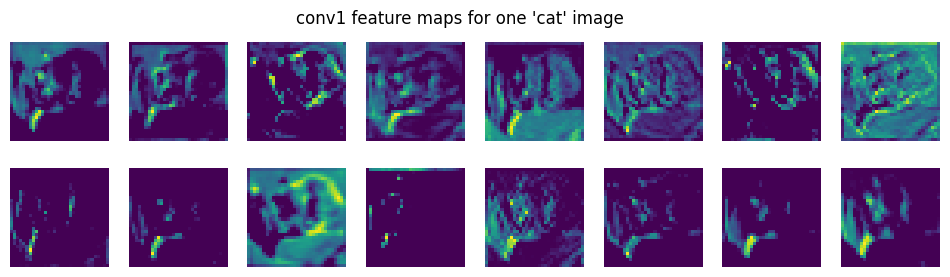

In [ ]:
# Fetch the very first image and its numerical label from the test dataset
image, label = test_set[0]

# Disable gradient tracking to conserve memory and optimize performance during forward pass
with torch.no_grad():
    # unsqueeze(0) adds a batch dimension: shape goes from (3, 32, 32) to (1, 3, 32, 32)
    # The output is passed through conv1, followed by a ReLU activation function
    # .cpu()[0] brings the tensor back to CPU and strips the batch dimension away
    maps = F.relu(
        model.conv1(image.unsqueeze(0).to(device))
    ).cpu()[0]

# Create a 2x8 grid layout of subplots to hold all 16 extracted feature maps
fig, axes = plt.subplots(2, 8, figsize=(12, 3))

# Flatten the subplot grid array to iterate over every axis and feature map together
for ax, fmap in zip(axes.flat, maps):
    # Render the 2D feature map using the 'viridis' colormap (good for highlighting intensities)
    ax.imshow(fmap, cmap="viridis")

    # Clean up the visualization by removing axis borders, lines, and tick marks
    ax.axis("off")

# Add a descriptive global title showing the ground truth class name of the chosen image
plt.suptitle(
    f"conv1 feature maps for one '{classes[label]}' image"
)

# Display the completed grid visualization window
plt.show()


# Lab Exercises

1. Change the Step 3 kernel to `[[1,1],[1,1]]`. Predict the feature map and state what pattern it detects.
2. Add `(32,4,1,1)` and `(7,3,2,0)` to Step 4. Explain the second result using the floor operation.
3. Change the upstream gradient in Step 7 to `[[1,1],[1,1]]` and observe both gradients.
4. Modify Step 8 to use a 3 × 3 kernel on a 4 × 4 input with all-one upstream gradient. Predict `dL/db`.
5. Add a third `32 → 64` convolution and a third pooling layer. Calculate the new flattened size.
6. Replace both max-pooling layers with average pooling and compare five-epoch accuracy.
7. Set `padding=0` in both convolution layers and trace the shapes.
8. Train for 15 epochs and record training loss and test accuracy.
9. Add `RandomHorizontalFlip()` to the training transform only and explain why.
10. Calculate MACs for `conv1` and `conv2` and compare them with their parameter counts.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

import numpy as np
import random
import math

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cpu


# Exercise 1
### Change the Step 3 kernel to `[[1,1],[1,1]]`
Predict the feature map and state what pattern it detects.

In [ ]:
X = torch.tensor([
    [1., 2., 0.],
    [0., 1., 3.],
    [2., 1., 0.]
])

K = torch.tensor([
    [1., 1.],
    [1., 1.]
])

feature_map = torch.zeros(2, 2)

for i in range(2):
    for j in range(2):
        region = X[i:i+2, j:j+2]
        feature_map[i, j] = torch.sum(region * K)

print("Feature map:")
print(feature_map)

print("\nPattern detected:")
print("Local sum/intensity of each 2x2 region.")


Feature map:
tensor([[4., 6.],
        [4., 5.]])

Pattern detected:
Local sum/intensity of each 2x2 region.


# Exercise 2
### Add `(32,4,1,1)` and `(7,3,2,0)`
Formula: `H_out = floor((H + 2P - K) / S) + 1`

In [ ]:
def conv_output_size(H, K, S, P):
    return math.floor((H + 2 * P - K) / S) + 1

for values in [(32, 4, 1, 1), (7, 3, 2, 0)]:
    H, K, S, P = values
    print(values, "->", conv_output_size(H, K, S, P))

print("\nFor (7,3,2,0):")
print("floor((7 + 0 - 3)/2) + 1 = floor(2) + 1 = 3")


(32, 4, 1, 1) -> 31
(7, 3, 2, 0) -> 3

For (7,3,2,0):
floor((7 + 0 - 3)/2) + 1 = floor(2) + 1 = 3


# Exercise 3
### Change the upstream gradient to `[[1,1],[1,1]]`
Observe max-pooling and average-pooling gradients.

In [ ]:
X = torch.tensor([
    [1., 9., 2., 4.],
    [3., 5., 7., 0.],
    [8., 6., 2., 1.],
    [4., 3., 9., 5.]
], requires_grad=True)

upstream = torch.ones(2, 2)

max_pool = F.max_pool2d(X[None, None], kernel_size=2, stride=2)
max_loss = (max_pool * upstream).sum()
max_loss.backward()
max_gradient = X.grad.detach().clone()

X.grad.zero_()

avg_pool = F.avg_pool2d(X[None, None], kernel_size=2, stride=2)
avg_loss = (avg_pool * upstream).sum()
avg_loss.backward()
avg_gradient = X.grad.detach().clone()

print("Max-pooling gradient:")
print(max_gradient)

print("\nAverage-pooling gradient:")
print(avg_gradient)


Max-pooling gradient:
tensor([[0., 1., 0., 0.],
        [0., 0., 1., 0.],
        [1., 0., 0., 0.],
        [0., 0., 1., 0.]])

Average-pooling gradient:
tensor([[0.2500, 0.2500, 0.2500, 0.2500],
        [0.2500, 0.2500, 0.2500, 0.2500],
        [0.2500, 0.2500, 0.2500, 0.2500],
        [0.2500, 0.2500, 0.2500, 0.2500]])


# Exercise 4
### 3×3 kernel on a 4×4 input with all-one upstream gradient
Predict `dL/db`.

In [ ]:
X = torch.arange(1., 17.).reshape(1, 1, 4, 4).requires_grad_()

conv = nn.Conv2d(1, 1, kernel_size=3, padding=0, bias=True)

with torch.no_grad():
    conv.weight.fill_(1.0)
    conv.bias.fill_(0.0)

Y = conv(X)
upstream = torch.ones_like(Y)

loss = (Y * upstream).sum()
loss.backward()

print("Output shape:", Y.shape)
print("Output:")
print(Y.detach().squeeze())

print("\ndL/db:", conv.bias.grad.item())
print("Expected: 4")


Output shape: torch.Size([1, 1, 2, 2])
Output:
tensor([[54., 63.],
        [90., 99.]])

dL/db: 4.0
Expected: 4


# Exercise 5
### Add a third `32 → 64` convolution and a third pooling layer
Calculate the new flattened size.

In [ ]:
class CNN_ThreeConv(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(64 * 4 * 4, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

model = CNN_ThreeConv()
dummy = torch.randn(1, 3, 32, 32)

with torch.no_grad():
    out = model(dummy)

print("Input shape :", dummy.shape)
print("Output shape:", out.shape)
print("Flattened size:", 64 * 4 * 4)


Input shape : torch.Size([1, 3, 32, 32])
Output shape: torch.Size([1, 10])
Flattened size: 1024


# Exercise 6
### Replace both max-pooling layers with average pooling
Train for five epochs and compare accuracy.

In [ ]:
class SimpleCNN_AvgPool(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.pool = nn.AvgPool2d(2, 2)
        self.fc1 = nn.Linear(32 * 8 * 8, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)


def get_cifar10_loaders(batch_size=64):   # CHANGED: 128 → 64
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(
            (0.5, 0.5, 0.5),
            (0.5, 0.5, 0.5)
        )
    ])

    trainset = torchvision.datasets.CIFAR10(
        root="./data",
        train=True,
        download=True,
        transform=transform
    )

    testset = torchvision.datasets.CIFAR10(
        root="./data",
        train=False,
        download=True,
        transform=transform
    )

    trainloader = DataLoader(
        trainset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=2
    )

    testloader = DataLoader(
        testset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2
    )

    return trainloader, testloader


def train_one_epoch(model, loader, optimizer, criterion):
    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, 100 * correct / total


def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, 100 * correct / total


# TRAIN

trainloader, testloader = get_cifar10_loaders(batch_size=64)

model_avg = SimpleCNN_AvgPool().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model_avg.parameters(),
    lr=1e-3
)

for epoch in range(5):

    train_loss, train_acc = train_one_epoch(
        model_avg,
        trainloader,
        optimizer,
        criterion
    )

    test_loss, test_acc = evaluate(
        model_avg,
        testloader,
        criterion
    )

    print(
        f"Epoch {epoch+1}/5 | "
        f"Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Test Acc: {test_acc:.2f}%"
    )

Epoch 1/5 | Loss: 1.5216 | Train Acc: 45.10% | Test Acc: 53.01%
Epoch 2/5 | Loss: 1.2058 | Train Acc: 56.92% | Test Acc: 59.55%
Epoch 3/5 | Loss: 1.0652 | Train Acc: 62.12% | Test Acc: 61.89%
Epoch 4/5 | Loss: 0.9603 | Train Acc: 66.21% | Test Acc: 64.13%
Epoch 5/5 | Loss: 0.8791 | Train Acc: 68.99% | Test Acc: 65.79%


The original Max Pooling CNN achieved about 68.94% test accuracy in the reference run, while the Average Pooling CNN achieved 65.79% in this run. Thus, Average Pooling gave a lower test accuracy under these training conditions.

# Exercise 7
### Set `padding=0` in both convolution layers and trace the shapes.

In [ ]:
class CNN_NoPadding(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 16, 3, padding=0)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=0)
        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(32 * 6 * 6, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.conv1(x)
        print("After Conv1 :", x.shape)

        x = self.pool(F.relu(x))
        print("After Pool1 :", x.shape)

        x = self.conv2(x)
        print("After Conv2 :", x.shape)

        x = self.pool(F.relu(x))
        print("After Pool2 :", x.shape)

        x = torch.flatten(x, 1)
        print("After Flatten:", x.shape)

        x = F.relu(self.fc1(x))
        return self.fc2(x)


model_no_padding = CNN_NoPadding()
dummy = torch.randn(1, 3, 32, 32)

print("Input       :", dummy.shape)
output = model_no_padding(dummy)
print("Final output:", output.shape)


Input       : torch.Size([1, 3, 32, 32])
After Conv1 : torch.Size([1, 16, 30, 30])
After Pool1 : torch.Size([1, 16, 15, 15])
After Conv2 : torch.Size([1, 32, 13, 13])
After Pool2 : torch.Size([1, 32, 6, 6])
After Flatten: torch.Size([1, 1152])
Final output: torch.Size([1, 10])


### Observation

With padding = 0, no zeros are added around the input.

For a 3×3 kernel with stride 1:

H_out = H - K + 1

Therefore, each convolution reduces the height and width by
2 pixels in total, meaning 1 pixel is lost from each side.

Shapes:

Input       : 3 × 32 × 32
After Conv1 : 16 × 30 × 30
After Pool1 : 16 × 15 × 15
After Conv2 : 32 × 13 × 13
After Pool2 : 32 × 6 × 6

Flattened size = 32 × 6 × 6 = 1152

Therefore, the fully connected layer must use:

nn.Linear(32 * 6 * 6, 128)

# Exercise 8
### Train for 15 epochs and record training loss and test accuracy.

In [ ]:
class SimpleCNN_MaxPool(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(32 * 8 * 8, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)


# TRAIN FOR 15 EPOCHS:

trainloader, testloader = get_cifar10_loaders()
model_15 = SimpleCNN_MaxPool().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_15.parameters(), lr=1e-3)

history_15 = []

for epoch in range(15):
    train_loss, train_acc = train_one_epoch(
        model_15, trainloader, optimizer, criterion
    )
    test_loss, test_acc = evaluate(
        model_15, testloader, criterion
    )

    history_15.append([
        epoch + 1, train_loss, train_acc, test_acc
    ])

    print(
        f"Epoch {epoch+1:02d}/15 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Test Acc: {test_acc:.2f}%"
    )


Epoch 01/15 | Train Loss: 1.5512 | Train Acc: 44.74% | Test Acc: 54.14%
Epoch 02/15 | Train Loss: 1.2105 | Train Acc: 57.18% | Test Acc: 60.23%
Epoch 03/15 | Train Loss: 1.0654 | Train Acc: 62.59% | Test Acc: 63.66%
Epoch 04/15 | Train Loss: 0.9611 | Train Acc: 66.48% | Test Acc: 65.80%
Epoch 05/15 | Train Loss: 0.8857 | Train Acc: 68.98% | Test Acc: 66.06%
Epoch 06/15 | Train Loss: 0.8195 | Train Acc: 71.33% | Test Acc: 67.81%
Epoch 07/15 | Train Loss: 0.7563 | Train Acc: 73.47% | Test Acc: 68.40%
Epoch 08/15 | Train Loss: 0.7035 | Train Acc: 75.37% | Test Acc: 68.61%
Epoch 09/15 | Train Loss: 0.6542 | Train Acc: 77.07% | Test Acc: 69.20%
Epoch 10/15 | Train Loss: 0.6079 | Train Acc: 78.74% | Test Acc: 68.59%
Epoch 11/15 | Train Loss: 0.5655 | Train Acc: 80.25% | Test Acc: 68.73%
Epoch 12/15 | Train Loss: 0.5167 | Train Acc: 81.95% | Test Acc: 69.58%
Epoch 13/15 | Train Loss: 0.4744 | Train Acc: 83.46% | Test Acc: 68.83%
Epoch 14/15 | Train Loss: 0.4347 | Train Acc: 84.87% | Test Acc:

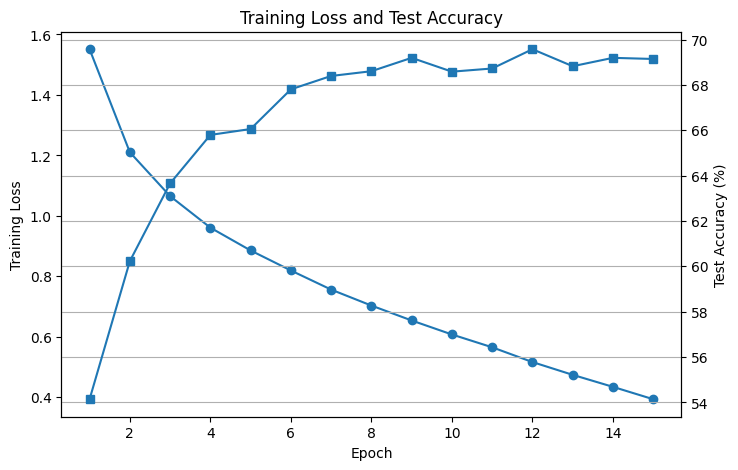

In [ ]:
import matplotlib.pyplot as plt

# Actual results from the 15-epoch training run
epochs = list(range(1, 16))

train_loss = [
    1.5512, 1.2105, 1.0654, 0.9611, 0.8857,
    0.8195, 0.7563, 0.7035, 0.6542, 0.6079,
    0.5655, 0.5167, 0.4744, 0.4347, 0.3938
]

test_acc = [
    54.14, 60.23, 63.66, 65.80, 66.06,
    67.81, 68.40, 68.61, 69.20, 68.59,
    68.73, 69.58, 68.83, 69.20, 69.15
]

fig, ax1 = plt.subplots(figsize=(8, 5))

# Training Loss
ax1.plot(
    epochs,
    train_loss,
    marker="o",
    label="Training Loss"
)
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Training Loss")

# Test Accuracy
ax2 = ax1.twinx()
ax2.plot(
    epochs,
    test_acc,
    marker="s",
    label="Test Accuracy"
)
ax2.set_ylabel("Test Accuracy (%)")

plt.title("Training Loss and Test Accuracy")
plt.grid(True)
plt.show()

Training loss continuously decreased from 1.5512 in Epoch 1 to 0.3938 in Epoch 15, while training accuracy increased from 44.74% to 86.38%. Test accuracy increased initially and reached a maximum of 69.58% at Epoch 12. After this point, test accuracy fluctuated around 69% while training performance continued to improve. This indicates that the curves begin to diverge in the later epochs, showing signs of overfitting.

# Exercise 9
### Add `RandomHorizontalFlip()` to the training transform only.

In [ ]:
# Training transform: add random horizontal flipping
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5),
                         (0.5, 0.5, 0.5))
])

# Test transform: NO random augmentation
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5),
                         (0.5, 0.5, 0.5))
])

# Create new datasets with the correct transforms
aug_train_set = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=train_transform
)

aug_test_set = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=False,
    transform=test_transform
)

# Create new DataLoaders
aug_train_loader = torch.utils.data.DataLoader(
    aug_train_set,
    batch_size=64,
    shuffle=True
)

aug_test_loader = torch.utils.data.DataLoader(
    aug_test_set,
    batch_size=64,
    shuffle=False
)

# Create a fresh model
aug_model = SmallCNN().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    aug_model.parameters(),
    lr=1e-3
)

# Train for 5 epochs
EPOCHS = 5

for epoch in range(1, EPOCHS + 1):

    aug_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in aug_train_loader:

        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = aug_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predicted = outputs.argmax(dim=1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / len(aug_train_set)
    train_acc = 100 * correct / total

    print(
        f"epoch {epoch} | "
        f"training loss {train_loss:.4f} | "
        f"training accuracy {train_acc:.2f}%"
    )


# Evaluate on the original, non-augmented test images
aug_model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in aug_test_loader:

        images, labels = images.to(device), labels.to(device)

        outputs = aug_model(images)
        predicted = outputs.argmax(dim=1)

        correct += (predicted == labels).sum().item()
        total += labels.size(0)

aug_test_accuracy = 100 * correct / total

print(f"Test accuracy with horizontal flip: {aug_test_accuracy:.2f}%")

epoch 1 | training loss 1.4420 | training accuracy 48.23%
epoch 2 | training loss 1.1144 | training accuracy 60.54%
epoch 3 | training loss 0.9772 | training accuracy 65.48%
epoch 4 | training loss 0.8835 | training accuracy 68.93%
epoch 5 | training loss 0.8238 | training accuracy 70.98%
Test accuracy with horizontal flip: 69.29%


Observation:

Random horizontal flipping was applied only to the training dataset to introduce additional variation and improve generalization. The test dataset was kept unchanged to provide a consistent evaluation. The model achieved 69.29% test accuracy after applying horizontal flip augmentation.

# Exercise 10
### Calculate MACs for `conv1` and `conv2` and compare them with parameter counts.

Formula:

`MACs = H_out × W_out × K × K × C_in × C_out`


In [ ]:
def conv_macs(H_out, W_out, K, C_in, C_out):
    return H_out * W_out * K * K * C_in * C_out


def conv_parameters(K, C_in, C_out, bias=True):
    weights = K * K * C_in * C_out
    biases = C_out if bias else 0
    return weights + biases


conv1_macs = conv_macs(32, 32, 3, 3, 16)
conv1_params = conv_parameters(3, 3, 16)

conv2_macs = conv_macs(16, 16, 3, 16, 32)
conv2_params = conv_parameters(3, 16, 32)

print("Conv1")
print("MACs       :", conv1_macs)
print("Parameters :", conv1_params)

print("\nConv2")
print("MACs       :", conv2_macs)
print("Parameters :", conv2_params)

print("\nMACs / parameter count")
print("Conv1:", conv1_macs / conv1_params)
print("Conv2:", conv2_macs / conv2_params)

print("\nFinal:")
print("Conv1 = 442,368 MACs and 448 parameters")
print("Conv2 = 1,179,648 MACs and 4,640 parameters")


Conv1
MACs       : 442368
Parameters : 448

Conv2
MACs       : 1179648
Parameters : 4640

MACs / parameter count
Conv1: 987.4285714285714
Conv2: 254.2344827586207

Final:
Conv1 = 442,368 MACs and 448 parameters
Conv2 = 1,179,648 MACs and 4,640 parameters


MACs → computational cost
Parameters → number of learnable values

# Quick Revision Table

| Concept | Key point |
|---|---|
| Tensor format | N, C, H, W |
| ReLU | `max(0, x)` |
| Conv output | `floor((H + 2P - K)/S) + 1` |
| Max pooling | Keeps maximum |
| Average pooling | Takes mean |
| Conv parameters | `K×K×Cin×Cout + Cout` |
| Receptive field | Input region affecting an activation |
| MACs | Multiply-accumulate operations |
| Loss | CrossEntropyLoss |
| Optimizer | Adam |
| Classifier output | 10 raw logits |
| Evaluation | `model.eval()` + `torch.no_grad()` |

# Conclusion

The practical verifies the main CNN operations with PyTorch: convolution, output-size calculation, ReLU, pooling, backpropagation, parameter counting and receptive fields. It then combines these components into a small CIFAR-10 image classifier.

### Overall CNN flow

```text
Image
  ↓
Convolution
  ↓
ReLU
  ↓
Pooling
  ↓
Convolution
  ↓
ReLU
  ↓
Pooling
  ↓
Flatten
  ↓
Fully Connected Layers
  ↓
10 Class Logits
  ↓
Cross-Entropy Loss
```

# Viva Questions

### 1. Why does `F.conv2d` require a four-dimensional tensor when the mathematical formula is two-dimensional?

`F.conv2d` expects input in the form `(Batch, Channels, Height, Width)`.
The mathematical convolution may be 2D, but CNNs process multiple images and channels at once.

Example:
`(1, 3, 32, 32)` = 1 image, 3 channels, 32×32 pixels.

---

### 2. What does `optimizer.zero_grad()` do, and what happens if it is omitted?

`optimizer.zero_grad()` clears the gradients from the previous iteration.

If it is omitted, PyTorch accumulates the new gradients with the old ones, causing incorrect parameter updates.

---

### 3. Why is there no softmax at the end of `SmallCNN.forward()`?

Because `nn.CrossEntropyLoss()` already applies the required softmax operation internally.

The model should therefore return the raw logits.

---

### 4. Why is model.eval() called before testing?

model.eval() switches the model to evaluation mode.
It is important for layers such as Dropout and BatchNorm.
Although this particular CNN does not contain these layers,
using model.eval() is the correct practice during testing.

---

### 5. Why does the centre entry of `dL/dX` become 2 in Step 8?

The centre input contributes to two different output positions.

Therefore, its gradient is received from both paths:

`1 + 1 = 2`

So the centre entry of `dL/dX` becomes 2.

---

### 6. Why do many cells receive zero gradient in max pooling?

Only the maximum element in each pooling window receives the
gradient. The other elements receive zero gradient because they
did not contribute to the selected maximum value.

---

### 7. Which part is more likely to overfit?

The fully connected layer fc1 is more likely to overfit because
it contains a large number of parameters.

fc1 parameters = 2048 × 128 + 128
                = 262,272

The convolution layers together have only 5,088 parameters.

Overfitting can be reduced using dropout, data augmentation,
weight decay, or a smaller fully connected layer.

---

### 8. Why does the final feature map become 8 × 8 even though the convolutions use padding?

Padding keeps the spatial size unchanged during convolution.

The size becomes `8 × 8` because the two `2 × 2` pooling layers each reduce the spatial dimensions by half:

`32 × 32 → 16 × 16 → 8 × 8`